In [24]:
import xarray as xr
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm

In [2]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
composite.svg
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc


In [3]:
version = 'DAV'
DSs = []
dics = []
np_arrays = []
for version in ['DAV','GHA']:
    DSs.append(xr.open_dataset('ERA5_northem_2.5x2.5_zg_'+version+'_tracked_daily_1940-2023.nc'))
    dics.append(np.load('dictionaries/ERA5_northem_2.5x2.5_zg_'+version+'_tracked_daily_1940-2023_DIC.npy',allow_pickle=True))
    np_arrays.append(DSs[-1][version+'_tracked'].values)

times = DSs[0]['time']
lats = DSs[0]['lat']
lons = DSs[0]['lon']

### selecting the events crossing Greenland

In [4]:
#Define rectangular mask and plon, plat
# Define the resolution
lat_resolution = 2.5  # 2.5 degrees
lon_resolution = 2.5  # 2.5 degrees

# Define the global latitude and longitude ranges
latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E

# Initialize a global mask with zeros
mask = np.zeros((len(latitudes), len(longitudes)))

# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 67, 80
lon_min, lon_max = -70, -20
plon = (lon_max + lon_min)/2
#plat = (lat_max + lat_min)/2

# Assign 1 to grid points within the bounding box
for i, lat in enumerate(latitudes):
    if lat_min <= lat <= lat_max:
        for j, lon in enumerate(longitudes):
            if lon_min <= lon <= lon_max:
                mask[i, j] = 1

# Convert the mask to an xarray DataArray
mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
mask_bool = mask_xr.data == 1

In [5]:
#create a list of labels for each IBI
#element 0 is DAV, 1 is GHA, 2 is MIX
dics_to_save = [[],[]]
labels = [[],[]]
timings = [[],[]]
min_pers = (3,3)
for t,time in tqdm(enumerate(times)):
    if t > len(times.values)-5:
        break
    for i,arr in enumerate(np_arrays):
        labels_of_the_day = np.unique(arr[t,mask_bool])
        for label in labels_of_the_day:
            check_cond = []
            for k in range(min_pers[i]):
                #check_cond.append(np.sum(arr[t+k,mask_bool]==label)/np.sum(mask_bool) > 0.1)
                check_cond.append(np.any(arr[t+k,mask_bool]==label))
            if label not in labels[i] and np.all(check_cond) and label!=0:
                dics_to_save[i].append(dics[i][label])
                dics_to_save[i][-1]['time_arrival_GR'] = t
                dics_to_save[i][-1]['day_arrival_GR'] = time
                dics_to_save[i][-1]['original_label'] = label
                labels[i].append(label)
                timings[i].append(t)
                dics[i][label]['day_of_arrival'] = time

30677it [00:16, 1818.69it/s]


### computing the WBI monthly distribution

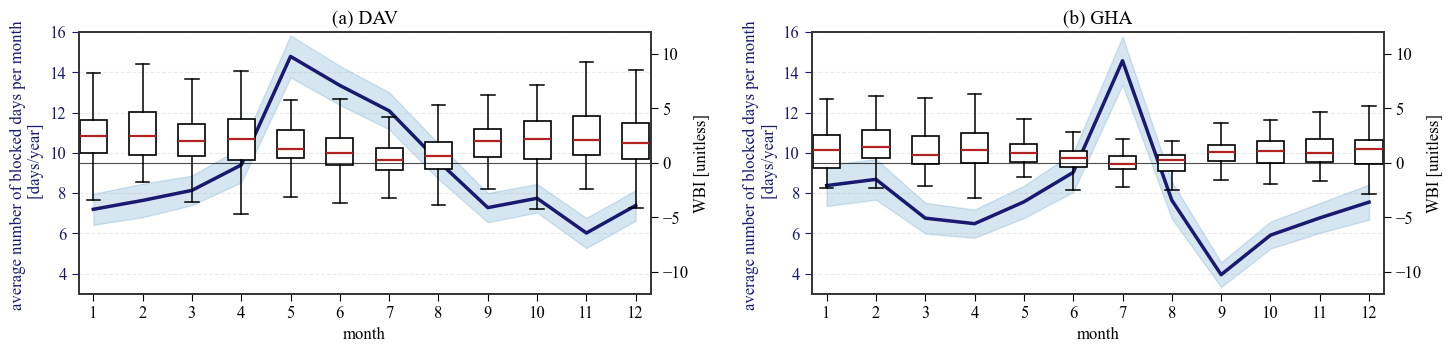

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# --- AESTHETIC SETTINGS -----------------------------------------------------
rcParams['axes.edgecolor'] = '0.2'
rcParams['axes.linewidth'] = 1.2
rcParams['font.size'] = 12
rcParams['xtick.major.size'] = 5
rcParams['ytick.major.size'] = 5

LINE_COLOR = 'midnightblue'#"#1f77b4"   # softer matplotlib blue
FILL_COLOR = "#1f77b4"
BOX_COLOR = "black"


# --- COMPUTATION FUNCTION --------------------------------------------------
def compute_monthly_stats(dic, start_year=1940, n_years=84):
    WBIs = [[] for _ in range(12)]
    N_events = np.zeros((n_years, 12))

    for element in dic:
        time = element['day_arrival_GR']
        year = int(str(time.values)[:4])
        month = int(str(time.values)[5:7]) - 1

        WBIs[month].append(np.mean(element['WBI']))
        N_events[year - start_year, month] += element['persistence']

    mean_cycle = N_events.mean(axis=0)
    std_cycle = N_events.std(axis=0) / np.sqrt(n_years)

    return WBIs, mean_cycle, std_cycle


# --- PANEL PLOT -----------------------------------------------------------
def plot_panel(ax, WBIs, mean_cycle, std_cycle, title):
    months = np.arange(1, 13)

    # --- Left axis: mean seasonal cycle ---
    ax.set_title(title, fontsize=14)

    ax.plot(
        months, mean_cycle,
        color=LINE_COLOR, linewidth=2.5
    )

    ax.fill_between(
        months,
        mean_cycle - std_cycle,
        mean_cycle + std_cycle,
        color=FILL_COLOR,
        alpha=0.18  # softer transparency
    )

    # Improve grid → only on left axis
    ax.grid(True, axis='y', linestyle='--', alpha=0.25)

    ax.set_ylabel('average number of blocked days per month \n [days/year]', color=LINE_COLOR)
    ax.set_xlabel('month')
    ax.set_xlim(0.7, 12.3)
    ax.set_ylim(3, 16)
    ax.tick_params(axis='y', colors=LINE_COLOR)

    # --- Right axis: Boxplot of WBI ---
    ax2 = ax.twinx()

    bp = ax2.boxplot(
        WBIs,
        showfliers=False,
        patch_artist=True,
        widths=0.55,
        medianprops=dict(color="firebrick", linewidth=1.6),
        boxprops=dict(facecolor="white", edgecolor="black", linewidth=1.2),
        whiskerprops=dict(color="black", linewidth=1.1),
        capprops=dict(color="black", linewidth=1.1),
    )

    # Softer zero line
    ax2.axhline(0, color='black', linewidth=0.8, alpha=0.7)

    ax2.set_ylabel('WBI [unitless]')
    ax2.set_ylim(-12, 12)

    return ax, ax2


# --- MAIN FIGURE ----------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(15, 4))

# Panel A — DAV
WBIs_DAV, mean_DAV, std_DAV = compute_monthly_stats(dics_to_save[0])
plot_panel(axs[0], WBIs_DAV, mean_DAV, std_DAV, "(a) DAV")

# Panel B — GHA
WBIs_GHA, mean_GHA, std_GHA = compute_monthly_stats(dics_to_save[1])
plot_panel(axs[1], WBIs_GHA, mean_GHA, std_GHA, "(b) GHA")

plt.tight_layout(pad=2.0)
plt.savefig(
    "/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/FigureA1.png",
    dpi=300,
    bbox_inches='tight'
)
plt.show()
